# 🚜 Predicting the Sale Price of Bulldozers using Machine Learning

End-to-end regression project: from raw auction records to price predictions for unseen future auctions.

## 1. Problem definition
> Given the characteristics of a piece of heavy equipment (bulldozer, excavator, loader…) and details of its sale,
> how well can we predict the price it will sell for at a **future** auction?

## 2. Data
Data comes from the Kaggle competition [Blue Book for Bulldozers](https://www.kaggle.com/c/bluebook-for-bulldozers/data).

| File | Contents | Period |
|---|---|---|
| `TrainAndValid.csv` | training + validation records, **with** `SalePrice` | 1989 – Apr 2012 |
| `Test.csv` | records we must price, **without** `SalePrice` | May – Nov 2012 |
| `Data Dictionary.xlsx` | meaning of each column | – |

The competition's split is **by time**: training data runs to the end of 2011, validation is Jan–Apr 2012, test is May–Nov 2012.
We copy that split, because the real job is to predict *future* prices.

## 3. Evaluation
The competition metric is **RMSLE** (Root Mean Squared Log Error):

$$\text{RMSLE} = \sqrt{\frac{1}{n}\sum_{i=1}^{n}\big(\log(1+\hat{y}_i) - \log(1+y_i)\big)^2}$$

RMSLE scores *relative* error, so being $5k off on a $10k machine counts for much more than $5k off on a $200k machine.
**Lower is better.** We also report MAE (in dollars) and R² because they are easier to explain.

## 4. Features
About 50 columns describing the machine (model, year made, hours used, size, enclosure, hydraulics…) and the sale (date, state, auctioneer).
Most of them are text categories, and many are largely empty. See `data/Data Dictionary.xlsx` for definitions.

In [1]:
import time
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.ensemble import RandomForestRegressor
from sklearn.model_selection import RandomizedSearchCV, TimeSeriesSplit
from sklearn.metrics import mean_absolute_error, r2_score, root_mean_squared_log_error

DATA_DIR = Path("data")
IMAGES_DIR = Path("images")
PREDICTIONS_DIR = Path("predictions")
IMAGES_DIR.mkdir(exist_ok=True)
PREDICTIONS_DIR.mkdir(exist_ok=True)

RANDOM_STATE = 42

# Plot styling: one accent colour, quiet axes and grid
BLUE, INK, MUTED = "#2a78d6", "#52514e", "#898781"
plt.rcParams.update({
    "figure.figsize": (9, 4.5), "figure.dpi": 110, "savefig.bbox": "tight",
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.edgecolor": MUTED, "axes.labelcolor": INK, "axes.titlecolor": INK,
    "axes.titleweight": "bold", "axes.titlelocation": "left",
    "xtick.color": MUTED, "ytick.color": MUTED,
    "axes.grid": True, "grid.color": "#e6e5e1", "grid.linewidth": 0.8, "axes.axisbelow": True,
})
print("pandas", pd.__version__, "| numpy", np.__version__)

pandas 3.0.5 | numpy 2.5.2


## 5. Load and explore the data
We tell pandas to parse `saledate` as a real datetime when it reads the file, so we can sort by it and pull date features out of it.

In [2]:
df = pd.read_csv(DATA_DIR / "TrainAndValid.csv", low_memory=False, parse_dates=["saledate"])
print(df.shape)
df.head().T

(412698, 53)


,0,1,2,3,4
SalesID,1139246,1139248,1139249,1139251,1139253
SalePrice,66000.0,57000.0,10000.0,38500.0,11000.0
MachineID,999089,117657,434808,1026470,1057373
ModelID,3157,77,7009,332,17311
datasource,121,121,121,121,121
auctioneerID,3.0,3.0,3.0,3.0,3.0
YearMade,2004,1996,2001,2001,2007
MachineHoursCurrentMeter,68.0,4640.0,2838.0,3486.0,722.0
UsageBand,Low,Low,High,High,Medium
saledate,2006-11-16 00:00:00,2004-03-26 00:00:00,2004-02-26 00:00:00,2011-05-19 00:00:00,2009-07-23 00:00:00


In [3]:
# Percentage of missing values per column: many columns are mostly empty
missing = (df.isna().mean() * 100).sort_values(ascending=False)
missing[missing > 0].round(1).head(25)

Pushblock            93.7
Tip_Control          93.7
Enclosure_Type       93.7
Engine_Horsepower    93.7
Blade_Extension      93.7
Blade_Width          93.7
Scarifier            93.7
Grouser_Tracks       89.1
Hydraulics_Flow      89.1
Coupler_System       89.1
fiModelSeries        85.8
Steering_Controls    82.7
Differential_Type    82.7
UsageBand            82.1
fiModelDescriptor    81.9
Backhoe_Mounting     80.4
Stick                80.3
Pad_Type             80.3
Turbocharged         80.3
Blade_Type           80.2
Travel_Controls      80.2
Tire_Size            76.3
Grouser_Type         75.2
Track_Type           75.2
Stick_Length         75.2
dtype: float64

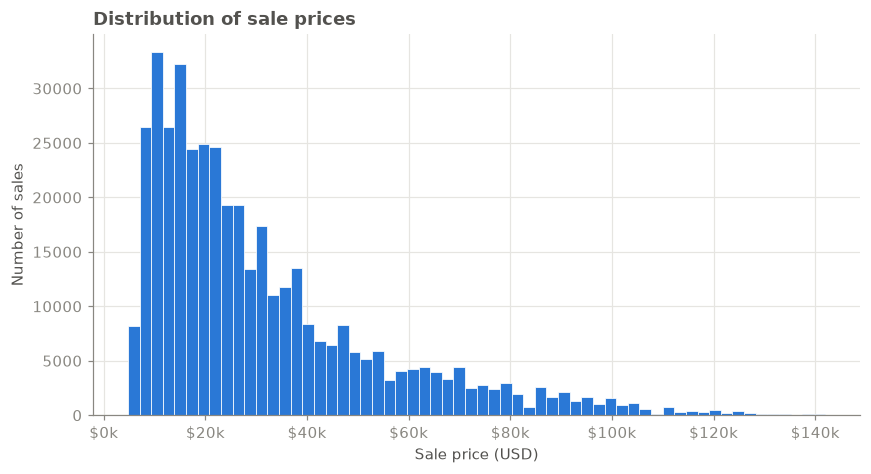

count    412698.0
mean      31215.0
std       23142.0
min        4750.0
25%       14500.0
50%       24000.0
75%       40000.0
max      142000.0
Name: SalePrice, dtype: float64


In [4]:
fig, ax = plt.subplots()
ax.hist(df["SalePrice"], bins=60, color=BLUE, edgecolor="white", linewidth=0.5)
ax.set(title="Distribution of sale prices", xlabel="Sale price (USD)", ylabel="Number of sales")
ax.xaxis.set_major_formatter(lambda x, _: f"${x/1000:.0f}k")
fig.savefig(IMAGES_DIR / "price_distribution.png")
plt.show()
print(df["SalePrice"].describe().round(0))

The target is **right-skewed**: most machines sell for $10k–$40k, with a long tail of expensive ones.
That skew is one reason the competition uses a *log*-based metric.

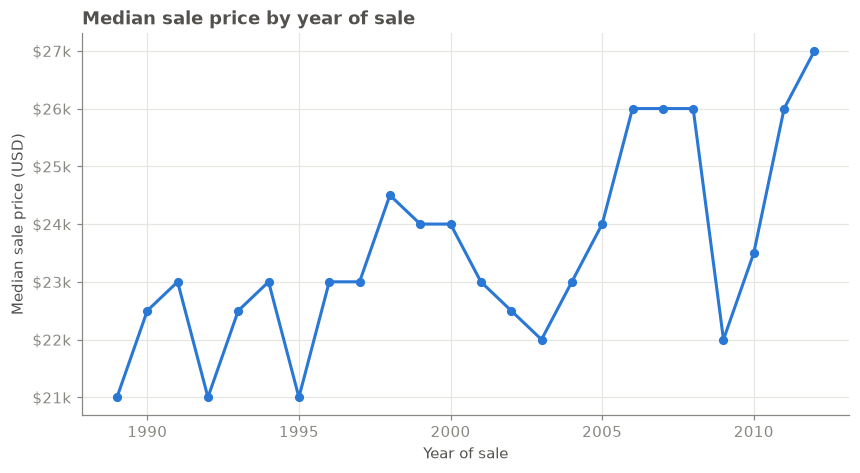

In [5]:
yearly = df.groupby(df["saledate"].dt.year)["SalePrice"].median()

fig, ax = plt.subplots()
ax.plot(yearly.index, yearly.values, color=BLUE, linewidth=2, marker="o", markersize=5)
ax.set(title="Median sale price by year of sale", xlabel="Year of sale", ylabel="Median sale price (USD)")
ax.yaxis.set_major_formatter(lambda x, _: f"${x/1000:.0f}k")
fig.savefig(IMAGES_DIR / "median_price_by_year.png")
plt.show()

Prices change over time, which is another reason to validate on *later* data rather than on a random shuffle.

In [6]:
# Data-quality check: YearMade has a placeholder value of 1000 for unknown years
print("Rows with YearMade == 1000:", (df["YearMade"] == 1000).sum())
print("Sales per state (top 5):")
df["state"].value_counts().head()

Rows with YearMade == 1000: 39391
Sales per state (top 5):


state
Florida       67320
Texas         53110
California    29761
Washington    16222
Georgia       14633
Name: count, dtype: int64

`YearMade == 1000` stands for "unknown". Tree-based models handle this on their own (they can put those rows in a separate split),
so we leave it as is. A linear model would need this value cleaned first.

## 6. Feature engineering: date features
A raw datetime means little to a model. We split it into numeric parts the model can split on:
year, month, day, day of week and day of year. Then we drop the original column.

In [7]:
# Sort by date: the data is a time series and our split depends on time
df = df.sort_values("saledate").reset_index(drop=True)

def add_date_features(df):
    # Expand `saledate` into numeric features and drop the raw datetime
    df = df.copy()
    df["saleYear"] = df["saledate"].dt.year
    df["saleMonth"] = df["saledate"].dt.month
    df["saleDay"] = df["saledate"].dt.day
    df["saleDayOfWeek"] = df["saledate"].dt.dayofweek
    df["saleDayOfYear"] = df["saledate"].dt.dayofyear
    return df.drop("saledate", axis=1)

df = add_date_features(df)
df[["saleYear", "saleMonth", "saleDay", "saleDayOfWeek", "saleDayOfYear"]].head()

,saleYear,saleMonth,saleDay,saleDayOfWeek,saleDayOfYear
0,1989,1,17,1,17
1,1989,1,31,1,31
2,1989,1,31,1,31
3,1989,1,31,1,31
4,1989,1,31,1,31


## 7. Train / validation split (by time)
As in the competition: **train = everything before 2012**, **validation = Jan–Apr 2012**.
A random split would let the model "see the future" and make validation scores look better than real-world performance.

In [8]:
df_train = df[df["saleYear"] < 2012]
df_valid = df[df["saleYear"] == 2012]

X_train_raw, y_train = df_train.drop("SalePrice", axis=1), df_train["SalePrice"]
X_valid_raw, y_valid = df_valid.drop("SalePrice", axis=1), df_valid["SalePrice"]

print(f"Train: {len(X_train_raw):,} rows ({df_train['saleYear'].min()}–{df_train['saleYear'].max()})")
print(f"Valid: {len(X_valid_raw):,} rows (2012)")

Train: 401,125 rows (1989–2011)
Valid: 11,573 rows (2012)


## 8. Preprocessing: missing values and categories → numbers
scikit-learn models need every value to be a number. Our preprocessing has two steps:

1. **Numeric columns**: fill missing values with the **median** of the training data, and add a `<col>_is_missing` flag column
   (whether a value was missing can itself predict the price).
2. **Text columns**: turn each one into a pandas category and use the category **code** (+1, so that *missing* becomes 0 rather than -1).
   We also add an `_is_missing` flag.

⚠️ **Key detail:** the medians and category lists are **learned from the training data only** (`fit_preprocessor`)
and then **re-used** on validation and test data (`transform`). If we encoded the test set separately,
"Florida" could be code 8 in training and code 5 in test, and the model would silently get the wrong input.
Learning only from training data also stops validation data from leaking in.

In [9]:
def fit_preprocessor(X):
    # Learn everything preprocessing needs from the TRAINING features only
    state = {"medians": {}, "categories": {}, "missing_flags": [], "columns": None}
    for label, content in X.items():
        if pd.api.types.is_numeric_dtype(content):
            state["medians"][label] = content.median()
        else:
            state["categories"][label] = pd.Categorical(content).categories
        if content.isna().any():
            state["missing_flags"].append(label)
    return state


def transform(X, state):
    # Apply learned preprocessing so train/valid/test all get the same encoding
    X = X.copy()
    for label in state["missing_flags"]:
        X[label + "_is_missing"] = X[label].isna()
    for label, median in state["medians"].items():
        X[label] = X[label].fillna(median)
    for label, categories in state["categories"].items():
        # Categories unseen in training are treated like missing values: code -1, so +1 maps them to 0
        known = X[label].where(X[label].isin(categories))
        X[label] = pd.Categorical(known, categories=categories).codes + 1
    if state["columns"] is None:
        state["columns"] = list(X.columns)
    return X[state["columns"]]  # identical column order every time


prep_state = fit_preprocessor(X_train_raw)
X_train = transform(X_train_raw, prep_state)
X_valid = transform(X_valid_raw, prep_state)

print("Features after preprocessing:", X_train.shape[1])
print("Any missing values left?", X_train.isna().any().any() or X_valid.isna().any().any())
print("All columns numeric/bool?", all(pd.api.types.is_numeric_dtype(t) or t == bool for t in X_train.dtypes))

Features after preprocessing: 96
Any missing values left? False
All columns numeric/bool? True


## 9. Evaluation function and a baseline
Before training a real model we need a **baseline** to beat: always predicting the median training price.
If our model can't beat that, it hasn't learned anything useful.

In [10]:
def show_scores(model, X_train, y_train, X_valid, y_valid):
    # Return the main regression metrics on the training and validation sets
    train_preds = model.predict(X_train)
    val_preds = model.predict(X_valid)
    return {
        "train_rmsle": root_mean_squared_log_error(y_train, train_preds),
        "valid_rmsle": root_mean_squared_log_error(y_valid, val_preds),
        "train_mae": mean_absolute_error(y_train, train_preds),
        "valid_mae": mean_absolute_error(y_valid, val_preds),
        "train_r2": r2_score(y_train, train_preds),
        "valid_r2": r2_score(y_valid, val_preds),
    }

baseline_preds = np.full(len(y_valid), y_train.median())
baseline_scores = {
    "valid_rmsle": root_mean_squared_log_error(y_valid, baseline_preds),
    "valid_mae": mean_absolute_error(y_valid, baseline_preds),
    "valid_r2": r2_score(y_valid, baseline_preds),
}
baseline_scores

{'valid_rmsle': 0.744140670869942,
 'valid_mae': 19697.331996889312,
 'valid_r2': -0.18319179446801703}

## 10. Model 1: Random Forest with default settings
**Why a Random Forest?**
- Works well on **tabular data** with a mix of numeric and category-coded features.
- It doesn't need feature scaling, copes with outliers, and handles placeholder values such as `YearMade == 1000`.
- It averages many decorrelated decision trees, so it overfits less than a single tree.
- It reports **feature importances**, which helps us explain the model.

In [11]:
start = time.time()
rf_default = RandomForestRegressor(n_jobs=-1, random_state=RANDOM_STATE)
rf_default.fit(X_train, y_train)
print(f"Training took {time.time() - start:.0f}s")

default_scores = show_scores(rf_default, X_train, y_train, X_valid, y_valid)
default_scores

Training took 88s


{'train_rmsle': 0.084263693222091,
 'valid_rmsle': 0.2567639804669143,
 'train_mae': 1578.5530188843877,
 'valid_mae': 6139.563590253175,
 'train_r2': 0.9875106667234307,
 'valid_r2': 0.8705743490325814}

Training RMSLE is much lower than validation RMSLE, so the default forest is **overfitting** (its trees grow until every leaf is pure).
Hyperparameter tuning should help.

## 11. Hyperparameter tuning with RandomizedSearchCV
Two choices keep the search fast and honest:
- **`max_samples=10_000`**: each tree trains on a 10k-row sample. That makes each fit very fast, so we can try many combinations.
- **`TimeSeriesSplit`**: cross-validation folds always train on earlier data and score on later data, matching the real task.
  (Plain K-fold would mix future sales into training.)

In [12]:
param_grid = {
    "n_estimators": [40, 60, 80, 100],
    "max_depth": [None, 10, 20, 30],
    "min_samples_split": np.arange(2, 21, 2),
    "min_samples_leaf": np.arange(1, 10),
    "max_features": [0.5, 1.0, "sqrt", "log2"],
    "max_samples": [10_000],
}

start = time.time()
rs_model = RandomizedSearchCV(
    RandomForestRegressor(n_jobs=-1, random_state=RANDOM_STATE),
    param_distributions=param_grid,
    n_iter=30,
    cv=TimeSeriesSplit(n_splits=3),
    scoring="neg_root_mean_squared_log_error",
    random_state=RANDOM_STATE,
    verbose=1,
)
rs_model.fit(X_train, y_train)
print(f"Search took {time.time() - start:.0f}s")
print("Best params:", rs_model.best_params_)
print("Best CV RMSLE:", round(-rs_model.best_score_, 4))

Fitting 3 folds for each of 30 candidates, totalling 90 fits


Search took 85s
Best params: {'n_estimators': 80, 'min_samples_split': np.int64(6), 'min_samples_leaf': np.int64(4), 'max_samples': 10000, 'max_features': 0.5, 'max_depth': None}
Best CV RMSLE: 0.3693


The search found good *structural* settings (how many features each split considers, minimum leaf size…) on small samples.
Now we train a forest with those settings on the **full** training set (`max_samples=None`) and compare it with the default model.

In [13]:
tuned_params = {k: v for k, v in rs_model.best_params_.items() if k != "max_samples"}
tuned_params["n_estimators"] = 100  # more trees on the full data: never hurts accuracy, only costs time

start = time.time()
rf_tuned = RandomForestRegressor(**tuned_params, n_jobs=-1, random_state=RANDOM_STATE)
rf_tuned.fit(X_train, y_train)
print(f"Training took {time.time() - start:.0f}s")

tuned_scores = show_scores(rf_tuned, X_train, y_train, X_valid, y_valid)
tuned_scores

Training took 47s


{'train_rmsle': 0.1429280449976124,
 'valid_rmsle': 0.2429975253413391,
 'train_mae': 2854.3476209694045,
 'valid_mae': 5916.902010730044,
 'train_r2': 0.9594082543900769,
 'valid_r2': 0.8817647604332219}

## 12. Compare models

In [14]:
comparison = pd.DataFrame({
    "Median baseline": baseline_scores,
    "RF default": default_scores,
    "RF tuned": tuned_scores,
}).T[["valid_rmsle", "valid_mae", "valid_r2", "train_rmsle"]]
comparison.round(4)

,valid_rmsle,valid_mae,valid_r2,train_rmsle
Median baseline,0.7441,19697.3320,-0.1832,NaN
RF default,0.2568,6139.5636,0.8706,0.0843
RF tuned,0.2430,5916.9020,0.8818,0.1429


In [15]:
# Pick the model with the lowest validation RMSLE
candidates = {"RF default": (rf_default, default_scores), "RF tuned": (rf_tuned, tuned_scores)}
best_name = min(candidates, key=lambda name: candidates[name][1]["valid_rmsle"])
best_model = candidates[best_name][0]
improvement = 1 - candidates[best_name][1]["valid_rmsle"] / baseline_scores["valid_rmsle"]
print(f"Best model: {best_name} | valid RMSLE {candidates[best_name][1]['valid_rmsle']:.4f} "
      f"({improvement:.0%} lower error than the median baseline)")

Best model: RF tuned | valid RMSLE 0.2430 (67% lower error than the median baseline)


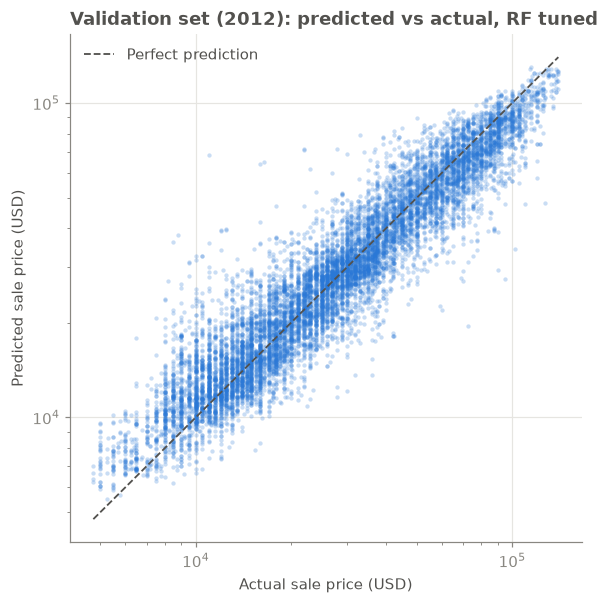

In [16]:
val_preds = best_model.predict(X_valid)

fig, ax = plt.subplots(figsize=(6, 6))
ax.scatter(y_valid, val_preds, s=8, alpha=0.25, color=BLUE, linewidths=0)
lims = [min(y_valid.min(), val_preds.min()), max(y_valid.max(), val_preds.max())]
ax.plot(lims, lims, color=INK, linewidth=1.2, linestyle="--", label="Perfect prediction")
ax.set(xscale="log", yscale="log", xlabel="Actual sale price (USD)", ylabel="Predicted sale price (USD)",
       title=f"Validation set (2012): predicted vs actual, {best_name}")
ax.legend(frameon=False, labelcolor=INK)
fig.savefig(IMAGES_DIR / "predicted_vs_actual.png")
plt.show()

## 13. Feature importance: what drives the price?

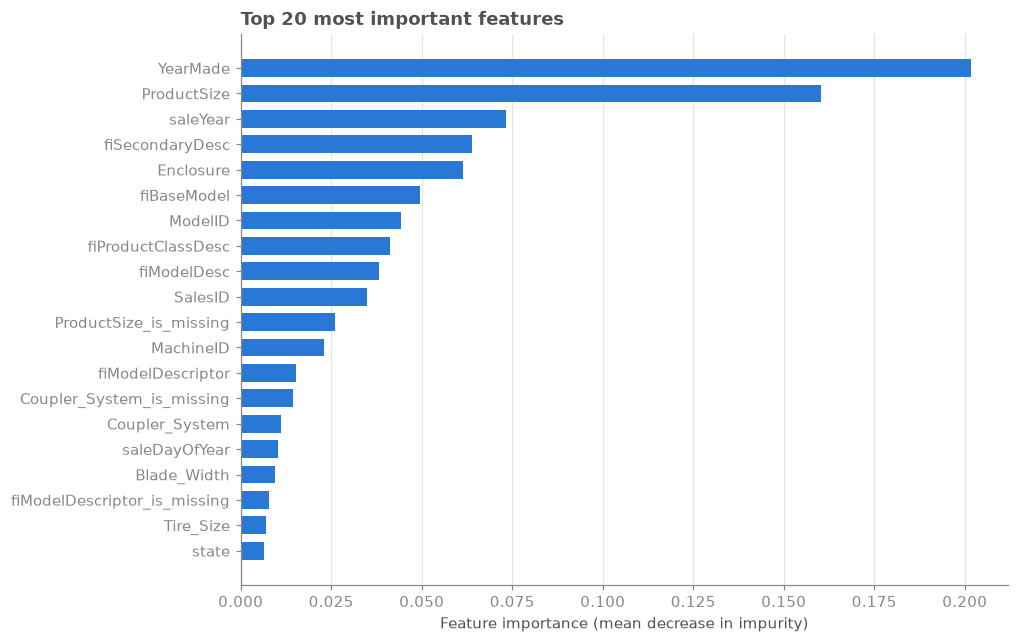

YearMade              0.202
ProductSize           0.160
saleYear              0.073
fiSecondaryDesc       0.064
Enclosure             0.061
fiBaseModel           0.050
ModelID               0.044
fiProductClassDesc    0.041
fiModelDesc           0.038
SalesID               0.035
dtype: float64

In [17]:
importances = (pd.Series(best_model.feature_importances_, index=X_train.columns)
               .sort_values(ascending=False))

top = importances.head(20)[::-1]
fig, ax = plt.subplots(figsize=(9, 6.5))
ax.barh(top.index, top.values, color=BLUE, height=0.7)
ax.set(title="Top 20 most important features", xlabel="Feature importance (mean decrease in impurity)")
ax.grid(axis="y", visible=False)
fig.savefig(IMAGES_DIR / "feature_importance.png")
plt.show()

importances.head(10).round(3)

The most important features make business sense:
- **`YearMade` / `saleYear`**: together they give the machine's **age** at sale, the main driver of depreciation.
- **`ProductSize`, `fiSecondaryDesc`, `fiBaseModel`, `fiProductClassDesc`, `fiModelDesc`**: what kind and size of machine it is.
  A large track-type tractor costs far more than a mini excavator.
- **`Enclosure`** (e.g. an enclosed cab with A/C vs an open cab): an option that adds value.
- **`ModelID`**: specific models hold their value differently.

`SalesID` and `MachineID` also appear in the top 20. They are just identifiers, but IDs were handed out over time,
so they partly act as a stand-in for the date. That is a reason to try dropping them in a future version.

## 14. Final model: retrain on all labelled data and predict the test set
Validation is done, so we retrain the chosen configuration on **train + validation** (all data up to April 2012).
The test set (May–Nov 2012) is closest in time to the validation period, so that recent data matters most.
The preprocessing is re-fitted on the same full data, then applied to the test set.

In [18]:
df_test_raw = pd.read_csv(DATA_DIR / "Test.csv", low_memory=False, parse_dates=["saledate"])
X_test_raw = add_date_features(df_test_raw)

X_all_raw, y_all = df.drop("SalePrice", axis=1), df["SalePrice"]
final_state = fit_preprocessor(X_all_raw)
X_all = transform(X_all_raw, final_state)
X_test = transform(X_test_raw, final_state)
assert list(X_test.columns) == list(X_all.columns)

start = time.time()
final_model = RandomForestRegressor(**best_model.get_params())
final_model.fit(X_all, y_all)
print(f"Final model trained on {len(X_all):,} rows in {time.time() - start:.0f}s")

test_preds = final_model.predict(X_test)
submission = pd.DataFrame({"SalesID": df_test_raw["SalesID"], "SalePrice": test_preds})
submission.to_csv(PREDICTIONS_DIR / "test_predictions.csv", index=False)
print(f"Saved {len(submission):,} predictions to {PREDICTIONS_DIR / 'test_predictions.csv'}")
submission.head()

Final model trained on 412,698 rows in 108s
Saved 12,457 predictions to predictions\test_predictions.csv


,SalesID,SalePrice
0,1227829,16225.740419
1,1227844,29902.537834
2,1227847,50785.059996
3,1227848,95733.568473
4,1227863,27187.108516


In [19]:
# Sanity check: predicted test prices should look like the historical ones
pd.DataFrame({"train SalePrice": y_all.describe(), "predicted test SalePrice": submission["SalePrice"].describe()}).round(0)

,train SalePrice,predicted test SalePrice
count,412698.0,12457.0
mean,31215.0,33589.0
std,23142.0,23853.0
min,4750.0,5322.0
25%,14500.0,14948.0
50%,24000.0,25940.0
75%,40000.0,45012.0
max,142000.0,130135.0


## 15. Conclusions
- We built an end-to-end regression pipeline: **EDA → date feature engineering → leak-free preprocessing → time-based validation → model tuning → feature importance → test predictions**.
- The Random Forest cuts validation RMSLE by **67%** compared with always predicting the median (0.744 → 0.243) (see the comparison table above).
- The most important features (age, product class/size, model) match how equipment is valued in the real world.

### Possible next steps
- **Target transform**: train on `log1p(SalePrice)` so the model optimises the RMSLE metric directly.
- **Gradient boosting** (LightGBM / XGBoost / CatBoost), which usually beats Random Forests on tabular data.
- **More features**: machine age (`saleYear - YearMade`), the `Machine_Appendix.csv` file (corrected machine attributes), and cleaning `YearMade == 1000`.
- **Drop low-importance / ID-like columns** to make a simpler, faster model.
- **Deploy**: save the model and preprocessing state with `joblib` and serve predictions from a small FastAPI or Streamlit app.